# Stability selection

:::{note} R binding
Stability selection (`stabsel()`) is available for `glmboost`, `gamboost`,
`glmboostLSS`, and `gamboostLSS` models in the R binding.
:::

Stability selection {cite}`meinshausen2010stability,hofner2015controlling` turns
boosting's selection path into a variable-selection procedure with **finite-sample
error control**: it refits on many subsamples and keeps only the learners
selected often enough to bound the expected number of false positives (PFER).

In [1]:
import numpy as np
import mboostrs as mb

rng = np.random.default_rng(2)
n, p = 200, 50
X = rng.normal(size=(n, p))
beta = np.zeros(p); beta[[1, 10, 25]] = [2.0, -2.0, 1.5]    # 3 true signals
y = X @ beta + rng.normal(scale=1.0, size=n)
data = {f"x{j}": X[:, j] for j in range(p)}; data["y"] = y
fit = mb.glmboost("y ~ " + " + ".join(f"x{j}" for j in range(p)),
                  data=data, family=mb.Gaussian(),
                  control=mb.boost_control(100, 0.1))

## Running `stabsel`

Specify any two of `q` (number of learners considered per subsample), `PFER`
(per-family error rate), and `cutoff` (selection-frequency threshold); the third
is implied.

In [2]:
sel = mb.stabsel(fit, q=8, PFER=1.0, B=50, verbose=False)
names = sel.learner_names
[names[i] for i in sel.selected]      # selected learners, by name

['x1', 'x10', 'x25']

The recovered set concentrates on the true signals (`x1`, `x10`, `x25`) while
controlling false positives — noise predictors rarely clear the cutoff.

## Selection frequencies

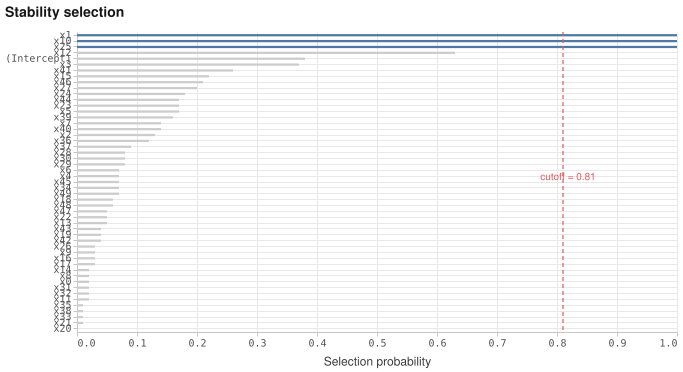

In [3]:
mb.plot.plot_stabsel(sel)

The dashed line is the cutoff: learners whose maximum selection frequency exceeds
it are considered stably selected. Here the three true signals (`x1`, `x10`,
`x25`) are well above the line, while noise predictors cluster below.

## Interpreting the parameters

Stability selection's guarantee is on the **expected number of false
selections** (PFER), not power. The three controlling parameters trade off:

| Parameter | Effect |
|---|---|
| `q` | Number of learners considered per subsample. Higher = more aggressive selection, looser bound. |
| `PFER` | Target expected false positives. Higher = less conservative. |
| `cutoff` | Selection-frequency threshold. Higher = more conservative. |

Specify any two; the third is implied by the error-control theorem.
The complementary-pairs sampler (`sampling_type="SS"`, the default) gives
the tightest bounds.

## Stability selection for `gamboost`

For smooth (`bbs`, `bspatial`) or mixed learner sets, pass the model to the
same function:

In [4]:
fit_gam = mb.gamboost("y ~ " + " + ".join(f"bbs(x{j}, df=4)" for j in range(p)),
                      data=data, family=mb.Gaussian(),
                      control=mb.boost_control(100, 0.1))
sel_gam = mb.stabsel(fit_gam, q=8, PFER=1.0, B=30, verbose=False)
selected_names = [sel_gam.learner_names[i] for i in sel_gam.selected]
print("GAMBoost selected:", selected_names[:5])

GAMBoost selected: ['x1', 'x10', 'x25']


## Screening with $p \gg n$

Stability selection targets the $p \gg n$ case that cross-validated `mstop`
does not bound well. Simulate a riboflavin-style screening problem — 300
candidates, 100 observations, only 5 true signals — and confirm the stable
set recovers them:

In [5]:
n_wide, p_wide = 100, 300
X_wide = rng.normal(size=(n_wide, p_wide))
beta_wide = np.zeros(p_wide)
true_idx = [3, 47, 122, 200, 288]
beta_wide[true_idx] = [2.0, -2.0, 1.5, 1.8, -1.5]
y_wide = X_wide @ beta_wide + rng.normal(scale=1.0, size=n_wide)
data_wide = {f"x{j}": X_wide[:, j] for j in range(p_wide)}
data_wide["y"] = y_wide

fit_wide = mb.glmboost("y ~ " + " + ".join(f"x{j}" for j in range(p_wide)),
                       data=data_wide, family=mb.Gaussian(),
                       control=mb.boost_control(mstop=200, nu=0.1))
sel_wide = mb.stabsel(fit_wide, q=10, PFER=2.0, B=50, verbose=False)
names_wide = np.array(sel_wide.learner_names)
print(f"p={p_wide}, n={n_wide}, cutoff={sel_wide.cutoff:.2f}")
print(f"selected: {sorted(names_wide[sel_wide.selected].tolist())}")
print(f"true:     {sorted(f'x{i}' for i in true_idx)}")


p=300, n=100, cutoff=0.55
selected: ['x122', 'x200', 'x288', 'x3', 'x47']
true:     ['x122', 'x200', 'x288', 'x3', 'x47']


## The `q`/`PFER`/`cutoff` trade-off

Fixing `q` and varying `PFER` traces out the derived `cutoff` — a higher
false-positive budget allows a lower (less conservative) threshold:

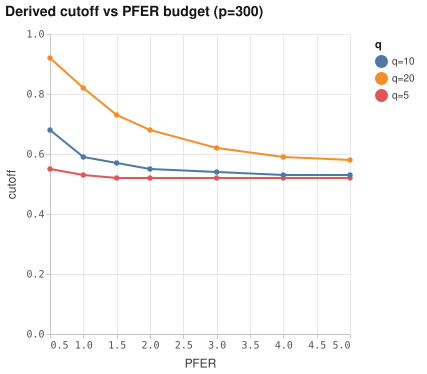

In [6]:
from mboostrs.stabsel import _stabsel_parameters
import polars as pl

pfer_grid = [0.5, 1, 1.5, 2, 3, 4, 5]
tradeoff_rows = []
for q_val in [5, 10, 20]:
    for pfer_val in pfer_grid:
        pars = _stabsel_parameters(p=p_wide, q=q_val, PFER=pfer_val, B=50,
                                    assumption="unimodal", sampling_type="SS")
        tradeoff_rows.append({"PFER": pfer_val, "cutoff": pars["cutoff"], "q": f"q={q_val}"})
tradeoff_pdf = pl.DataFrame(tradeoff_rows)

import altair as alt
alt.Chart(tradeoff_pdf).mark_line(point=True).encode(
    x="PFER:Q", y="cutoff:Q", color="q:N"
).properties(title=f"Derived cutoff vs PFER budget (p={p_wide})")


Larger `q` (more candidates considered per subsample) needs a higher cutoff
to hold the same PFER budget — this is the quadratic-in-`q` sharpness cost
from the bound (see [](../methodology/stability_selection)). Use this chart
to check a proposed `(q, PFER)` pair before running `B` subsamples.

## Deselection and probing: `deselect`, `probe`

Stability selection refits on 50 or more subsamples. Two cheaper procedures
from the boosting literature select from a single path. `mb.deselect(model,
threshold=0.01)` {cite}`stromer2022deselection` takes a fit at its tuned
step count, drops every learner whose share of the in-bag risk reduction
(what `varimp` reports) is below the threshold, and refits the remaining
terms with the step count cross-validated again. `mb.probe(formula, data)`
{cite}`thomas2017probing` adds a permuted copy of every single-column term,
fits once, and keeps the terms selected before the first copy: a permuted
column has its original's distribution and no relation to the response, so
its first selection marks where the fit starts taking up noise. Neither
bounds the number of false selections, which stability selection does.

In [7]:
formula = "y ~ " + " + ".join(f"x{j}" for j in range(p))
tuned = mb.tune_mstop(formula, data).model
deselected = mb.deselect(tuned)
probed = mb.probe(formula, data)
tuned_set = sorted(set(tuned.selected))
{"selected by the tuned fit": tuned_set,
 "kept by deselection": list(deselected.kept),
 "kept by probing": list(probed.selected),
 "first permuted column entered at step": probed.stop}

{'selected by the tuned fit': ['x1',
  'x10',
  'x12',
  'x25',
  'x29',
  'x3',
  'x41',
  'x44',
  'x48'],
 'kept by deselection': ['x1', 'x10', 'x25'],
 'kept by probing': ['x1', 'x10', 'x12', 'x25'],
 'first permuted column entered at step': 73}

The fit tuned by cross-validation selects {eval}`len(tuned_set)` columns,
of which three carry signal: the step count that predicts best is later
than the one that selects well, so a few noise columns pick up small
effects. Deselection keeps {eval}`len(deselected.kept)` and probing
{eval}`len(probed.selected)`; probing's first permuted column entered at
step {eval}`probed.stop`, and a noise column that entered before it stays in.

The results use different identifiers: `stabsel` reports learner indices
(`selected`) and names (`selected_names`), while `deselect` and `probe` report
formula terms (`kept`, `selected`). Each also reports `variables`, the data
columns read by its selected terms. `probe` also takes the fitted
model, as the other two do, and reuses its formula, data and family:

In [8]:
{"stabsel": mb.stabsel(tuned, PFER=1, cutoff=0.75, verbose=False).variables,
 "deselect": deselected.variables,
 "probe": mb.probe(tuned).variables}

{'stabsel': ('x1', 'x10', 'x25'),
 'deselect': ('x1', 'x10', 'x25'),
 'probe': ('x1', 'x10', 'x12', 'x25')}

Deselection also applies to a distributional model fitted with
`method="noncyclic"`, the setting it was proposed for. Each step of a
non-cyclic fit updates one learner of one parameter, so each step's risk
reduction belongs to one (learner, parameter) pair; shares are computed over
all parameters together, a parameter left with no term is refitted as
intercept-only (`y ~ 1`), and the refit's total step count is
cross-validated with `LSSModel.cvrisk`. A cyclic fit records the risk once
per cycle, after every parameter has moved, and is refused. Below, the mean
depends on `x1` and `x10` and the standard deviation on `x25`:

In [9]:
few = [f"x{j}" for j in (1, 10, 25, 3, 4, 5)]
sd = np.exp(0.6 * X[:, 25])
lss_data = {name: data[name] for name in few}
lss_data["y"] = 2.0 * X[:, 1] - 2.0 * X[:, 10] + sd * rng.normal(size=n)
lss_fit = mb.glmboostLSS("y ~ " + " + ".join(few), data=lss_data,
                         families=mb.GaussianLSS(),
                         control=mb.boost_control(400, 0.1), method="noncyclic")
lss_deselected = mb.deselect(lss_fit, mstop=3000)
lss_deselected.formula

{'mu': 'y ~ x1 + x10', 'sigma': 'y ~ x25'}

## See also

[](model_selection.ipynb) covers cross-validation-based stopping, and
[](../methodology/stability_selection) gives the derivation and error-control
theorem.